In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization

I0000 00:00:1791190884.055310   15846 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791190884.360822   15846 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791190886.254451   15846 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
(X_train,y_train),(X_test, y_test) = mnist.load_data()

In [3]:
X_train.shape

(60000, 28, 28)

In [4]:
X_test.shape

(10000, 28, 28)

In [5]:
X_train = X_train/255
X_test = X_test/255

In [6]:
X_train.shape

(60000, 28, 28)

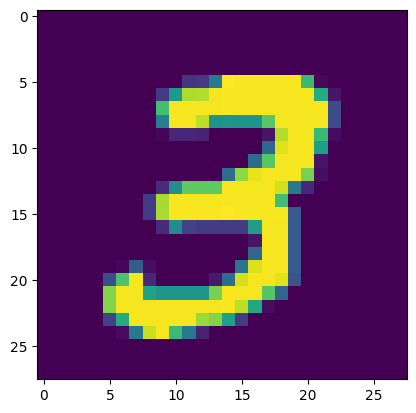

In [7]:
plt.imshow(X_train[7])
plt.show()

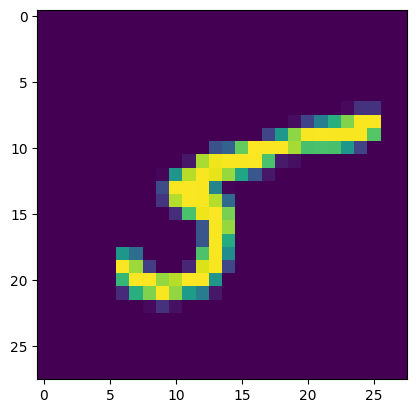

In [8]:
plt.imshow(X_train[65])
plt.show()

In [9]:
model = Sequential()
model.add(Flatten(input_shape = (28,28))) #high demision to lower if 2d to1d

model.add(Dense(256, activation = 'relu'))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(256, activation = 'relu'))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(10, activation = 'softmax'))

/home/hp/anaconda3/envs/tf_env/lib/python3.10/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
E0000 00:00:1791190890.254640   15846 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 271,370 (1.04 MB)

 Trainable params: 270,346 (1.03 MB)

 Non-trainable params: 1,024 (4.00 KB)

In [11]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [12]:
model.compile(optimizer = 'Adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [14]:
X_train.shape

(60000, 28, 28)

In [15]:
y_train.shape

(60000,)

In [16]:
history=model.fit(
    X_train,
    y_train,
    epochs=100,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/100


W0000 00:00:1791190895.966212   15846 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


1488/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8445 - loss: 0.5056

W0000 00:00:1791190902.873863   15846 cpu_allocator_impl.cc:82] Allocation of 37632000 exceeds 10% of free system memory.


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8969 - loss: 0.3360 - val_accuracy: 0.9576 - val_loss: 0.1372
Epoch 2/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9400 - loss: 0.1952 - val_accuracy: 0.9692 - val_loss: 0.1047
Epoch 3/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9516 - loss: 0.1560 - val_accuracy: 0.9699 - val_loss: 0.1037
Epoch 4/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9570 - loss: 0.1388 - val_accuracy: 0.9728 - val_loss: 0.0895
Epoch 5/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9617 - loss: 0.1208 - val_accuracy: 0.9738 - val_loss: 0.0836
Epoch 6/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9639 - loss: 0.1123 - val_accuracy: 0.9772 - val_loss: 0.0816
Epoch 7/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9663 - loss: 0.1057 - val_accuracy: 0.9778 - val_loss: 0.0749
Epoch 8/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9716 - loss: 0.0909 - val_

In [17]:
y_prob=model.predict(X_test)

 86/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

W0000 00:00:1791190961.209166   15846 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [21]:
from sklearn.metrics import accuracy_score
y_pred=y_prob.argmax(axis=1)
accuracy_score(y_test, y_pred)

0.9797

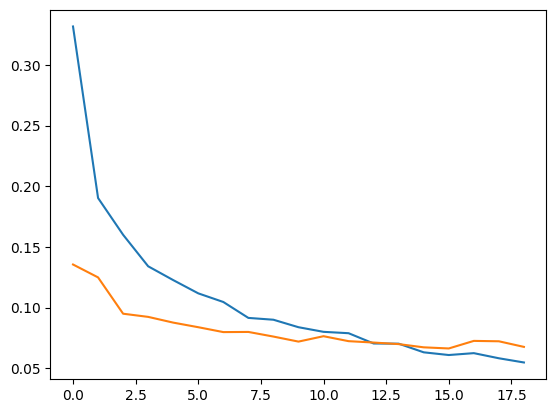

In [46]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.show()

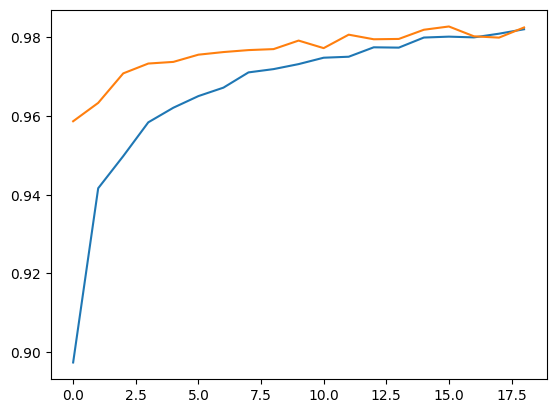

In [47]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.show()

In [48]:
model.predict(X_test[1].reshape(1,28,28)).argmax(axis = 1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


array([2])

In [19]:
model.save("mnist_model.keras")

In [32]:
i = 1
pred = model.predict(X_test[i].reshape(1, 28, 28), verbose=0)
print("Predicted:", int(pred.argmax()), "| True label:", y_test[i])


Predicted: 2 | True label: 2


In [33]:
from PIL import Image

i = 1
Image.fromarray((255 - X_test[i] * 255).astype("uint8")).save("my_digit.png")
print("True label:", y_test[i])


True label: 2


In [29]:
import cv2
import os
print(os.getcwd())
print(os.listdir())

/home/hp/anaconda3/deep learning/project
['Churn.ipynb', '.ipynb_checkpoints', 'handwriting.ipynb', 'mnist_model.keras', 'hand_writing.csv', 'hand_writing_MNIST.ipynb']


In [30]:
def preprocess_digit(img_bgr, min_area=100):
    """Extract a handwritten digit and format it like an MNIST sample.

    Returns (canvas, x) where canvas is a uint8 28x28 image (white digit on
    black, for display) and x is a float32 28x28 array in [0, 1] (model input).
    Returns (None, None) if no digit-like contour is found.
    """
    if img_bgr is None:
        raise ValueError("preprocess_digit got an empty image (None).")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)

    # Otsu picks the threshold automatically. maxval is 255 (not 2555),
    # and INVERT gives white-on-black, like MNIST.
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None, None

    # Use the LARGEST contour (the digit) -- not all contours merged together,
    # which on a webcam frame would just box the whole image.
    digit_cnt = max(contours, key=cv2.contourArea)
    if cv2.contourArea(digit_cnt) < min_area:
        return None, None

    x, y, w, h = cv2.boundingRect(digit_cnt)
    digit = thresh[y:y + h, x:x + w]

    # MNIST style: longest side -> 20 px, centered on a 28x28 canvas.
    if h > w:
        new_h, new_w = 20, max(1, int(round(w * 20 / h)))
    else:
        new_w, new_h = 20, max(1, int(round(h * 20 / w)))
    digit = cv2.resize(digit, (new_w, new_h), interpolation=cv2.INTER_AREA)

    canvas = np.zeros((28, 28), dtype=np.uint8)
    y_off, x_off = (28 - new_h) // 2, (28 - new_w) // 2
    canvas[y_off:y_off + new_h, x_off:x_off + new_w] = digit

    return canvas, canvas.astype("float32") / 255.0


Predicted digit: 4 | confidence: 0.9991


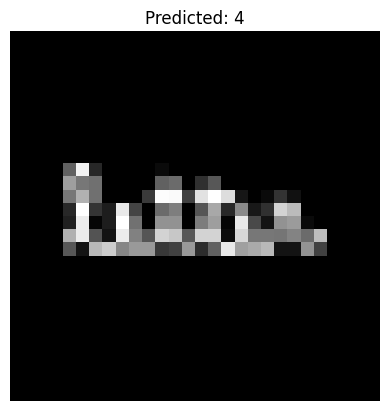

In [35]:
img = cv2.imread("handwriting.jpg")  # photo/scan of a handwritten digit
if img is None:
    raise FileNotFoundError(
        "my_digit.png not found. Put the image in the notebook's folder "
        f"(currently: {os.getcwd()}) or fix the path."
    )

canvas, x = preprocess_digit(img)
if x is None:
    raise ValueError("No digit found in the image - try better lighting or a thicker pen.")

pred = model.predict(x.reshape(1, 28, 28), verbose=0)
digit, conf = int(pred.argmax()), float(pred.max())
print(f"Predicted digit: {digit} | confidence: {conf:.4f}")

plt.imshow(canvas, cmap="gray")
plt.title(f"Predicted: {digit}")
plt.axis("off")
plt.show()


In [ ]:
cap = cv2.VideoCapture(0)
while True:
    ok, frame = cap.read()
    if not ok:
        break
    canvas, x = preprocess_digit(frame)
    if x is not None:
        p = model.predict(x.reshape(1, 28, 28), verbose=0)
        cv2.putText(frame, f"{p.argmax()} ({p.max():.2f})", (20, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 0), 3)
    cv2.imshow("Digit Recognition", frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break
cap.release()
cv2.destroyAllWindows()

QFontDatabase: Cannot find font directory /home/hp/anaconda3/envs/tf_env/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/hp/anaconda3/envs/tf_env/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/hp/anaconda3/envs/tf_env/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/hp/anaconda3/envs/tf_env/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font director